In [12]:
import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from google.colab import drive,userdata
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [3]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [4]:
r = get(baseUrl)

In [6]:
tng50d1 = get(baseUrl + "TNG50-1")
subhalo50d1_cutout = get(tng50d1['url'] + "/snapshots/33/subhalos/0/cutout.hdf5", {"gas":"Coordinates,Masses,MagneticField"})

In [7]:
with h5py.File(subhalo50d1_cutout,'r') as f:
  x = f['PartType0']['Coordinates'][:,0]
  y = f['PartType0']['Coordinates'][:,1]
  dens = np.log10(f['PartType0']['Masses'][:])
  header = dict(f['Header'].attrs)

In [8]:
with h5py.File(subhalo50d1_cutout,'r') as f:
  x = f['PartType0']['Coordinates'][:,0]
  y = f['PartType0']['Coordinates'][:,1]
  mag = f['PartType0']['MagneticField'][:]

In [9]:
scale_factor = 1.0 / (1.0 + header["Redshift"])
hubble_param = header['HubbleParam']
mag_physical = mag * hubble_param / scale_factor**2 * 2.6e-6 # https://www.tng-project.org/data/docs/specifications/

In [10]:
hubble_param

np.float64(0.6774)

In [11]:
mag_physical_magnitude = np.sqrt(mag_physical[:,0]**2 + mag_physical[:,1]**2 + mag_physical[:,2]**2)

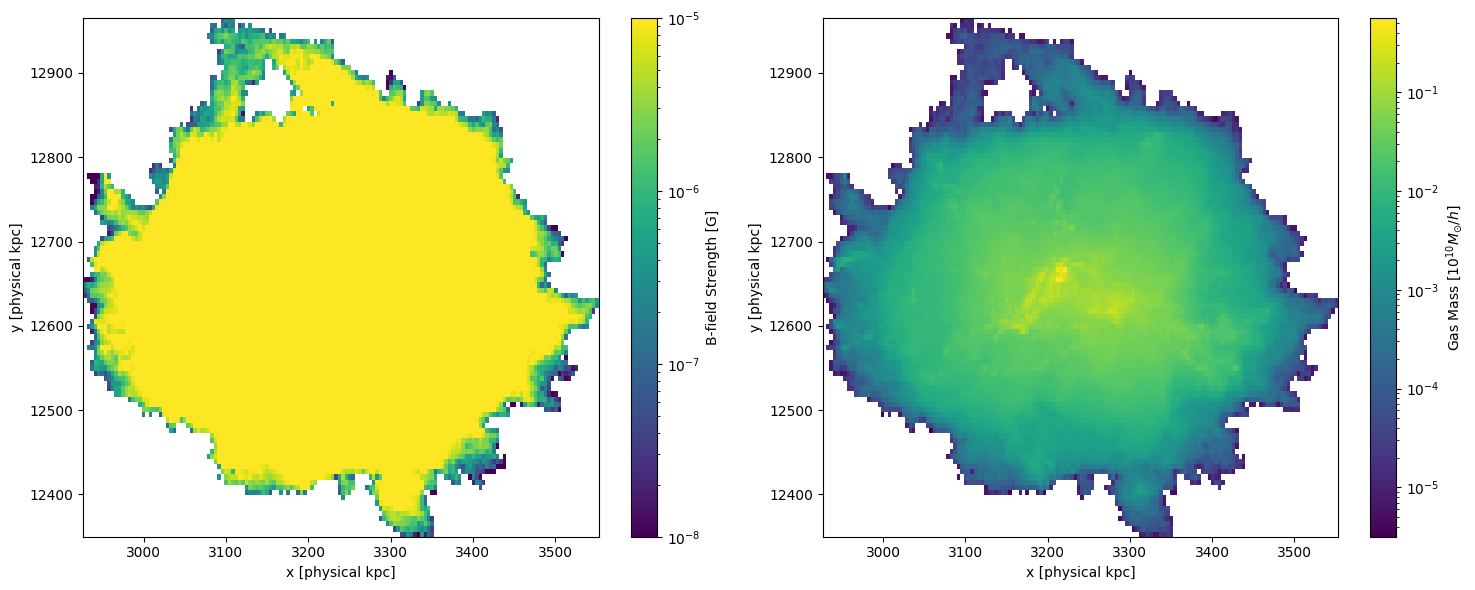

In [13]:
# Convert comoving coordinates (ckpc/h) to physical units (kpc)
x_physical = x * scale_factor / hubble_param
y_physical = y * scale_factor / hubble_param

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Magnetic Field Strength in physical units
im1 = ax1.hist2d(
    x_physical,
    y_physical,
    weights=mag_physical_magnitude,
    bins=[150, 100],
    norm=colors.LogNorm(vmin=1e-8, vmax=1e-5)
)
fig.colorbar(im1[3], ax=ax1, label='B-field Strength [G]')
ax1.set_xlabel('x [physical kpc]')
ax1.set_ylabel('y [physical kpc]')

im2 = ax2.hist2d(
    x_physical,
    y_physical,
    weights=10**dens,
    bins=[150, 100],
    norm=colors.LogNorm()
)
fig.colorbar(im2[3], ax=ax2, label='Gas Mass [$10^{10} M_{\\odot}/h$]')
ax2.set_xlabel('x [physical kpc]')
ax2.set_ylabel('y [physical kpc]')

plt.tight_layout()
plt.savefig("magXdens.png", dpi=300)
plt.show()